# When does the AI coder pick its algorithm? An audit: `eval.py` demo

**Research question.** How does "creativity" show up inside an LLM, and can we steer it toward genuinely different solutions? Asked to *implement path search*, does the model always write BFS? Six iteration-1 experiments put this to **Qwen3-8B** on two coding tasks:
- **T1**, an unweighted grid path, whose default answer is BFS;
- **T2**, a weighted shortest path, whose default is Dijkstra.

They varied temperature and top-k, context seeds (`seed=d32qxk4nt43`, `seed=(horse chair roof love)`), novelty instructions ("make a fully novel algorithm…"), bans on the top algorithms and activation steering, and they mapped the geometry of the hidden states.

**This artifact** is the round-one *audit* of those six experiments: no generation, no LLM calls, $0. Its entry point `eval.py` runs seven stage scripts and assembles their outputs into:
- `metrics_agg`: 80 headline scalars;
- `corrections.json`: every reviewer item, recomputed, with its source;
- `eval_out.json`: metadata plus four example datasets.

The audit has eight parts:
- **0a locus probe:** at which generated token and layer is the chosen algorithm linearly readable from the hidden state?
- **0b geometry:** which surviving algorithm is nearest the banned default on the activation manifold?
- **0c perturbation table**
- **0d record corrections and knob table:** does any prompt knob raise algorithm diversity?
- **0e seeds**
- **0f missing outputs**
- **0g sham bans**
- **0h positioning**

**What this notebook runs.** The stages need the six iteration-1 artifacts and 2 × 300 saved Qwen3-8B hidden states (8 positions × layers 8-28, GPU), so their outputs are shipped instead. `mini_demo_data.json` holds every stage output `eval.py` reads, trimmed to the fields it uses. The four row tables are cut to 99 curated rows, and the published `metrics_agg` is included for comparison.

The notebook runs `eval.py`'s own code on that bundle: the functions are verbatim and `main()` is split into five steps. It then checks the recomputed metrics against the published ones and plots:
- the activation-space PCA;
- the probe curves;
- the perturbation compositions;
- the knob table;
- the geometry.

It runs in about a minute, mostly the install cell.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import json
import math
import subprocess
import sys
import time

import numpy as np
import pandas as pd
from loguru import logger

# from common import HERE, RES, TAB, clean, jdump, setup_logging   -> defined in the "Helpers from common.py" cell below

# notebook additions: parse the bundled CSV text, paths, plotting
import io
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-2/evaluation-1/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print("bundle sections:", {k: list(v) for k, v in data.items() if k != "about"})
print("rows in the bundle:     ", data["about"]["rows_in_bundle"])
print("rows in the full tables:", data["published"]["full_row_counts"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
bundle sections: {'results': ['inventory.json', 'locus.json', 'geometry.json', 'tables.json', 'positioning.json', 'harmonise.json', 'figures.json', 'audit.json', 'audit_extra.json'], 'tables': ['perturbation_table.csv', 'knob_table.csv', 'locus_cells.csv'], 'iter1': ['exp3/forks.json'], 'published': ['metrics_agg', 'full_row_counts']}
rows in the bundle:      {'perturbation_table': 34, 'knob_table': 29, 'locus_cells': 16, 'geometry_grid': 20}
rows in the full tables: {'perturbation_table': 249, 'knob_table': 183, 'locus_cells': 903, 'geometry_grid': 56}


## Configuration

`eval.py` has one command-line option, `--rerun`, which re-runs every stage script before assembling. All the heavy compute lives in those stages, not in `eval.py`: IRLS probes with up to 400 permutation refits per probe cell (200 global + 200 within-paraphrase), and 1000-draw geometry subsampling.

Here the scale knob is how many rows of each table pass through the assembly, the analogue of `n_samples`. `None` keeps every row in the bundle. The full run uses the complete tables (249 / 183 / 903 rows), which only the stage scripts produce.

In [5]:
# ---- tunable parameters ----
RERUN = False               # eval.py --rerun: re-run all seven stage scripts first. Keep False here: the stage scripts, the six
                            # iteration-1 artifacts (ITER1_ROOT) and a GPU are not part of this demo (full run ~15 min on an RTX 4090)
MAX_PERTURBATION_ROWS = None  # rows of tables/perturbation_table.csv to assemble; None = all 34 bundled (full run: 249)
MAX_KNOB_ROWS = None          # rows of tables/knob_table.csv;                 None = all 29 bundled (full run: 183)
MAX_LOCUS_CELLS = None        # rows of tables/locus_cells.csv;                None = all 16 bundled (full run: 903)
# The geometry grid (20 of 56 cells bundled) is always used whole: geometry_section() looks up specific (layer, k) cells.

## Helpers from `common.py`

`eval.py` takes its paths and JSON helpers from the audit's `common.py`. The parts it uses are copied verbatim below. The one change: `HERE` is the notebook's working directory, because a notebook has no `__file__`.
- `setup_logging()` logs to the cell output and to `logs/eval.log`.
- `jdump()` writes JSON and handles numpy types.
- `clean()` replaces NaN/inf with `None`, so the output is strict JSON.

In [6]:
# excerpt of common.py: the names eval.py imports (HERE, RES, TAB, clean, jdump, setup_logging)
HERE = Path.cwd()  # common.py: Path(__file__).resolve().parent
RES = HERE / "results"
TAB = HERE / "tables"
LOG = HERE / "logs"
LOG.mkdir(exist_ok=True)  # common.py creates results/, tables/, figures/ and logs/; only logs/ is written here


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOG / f"{name}.log", rotation="30 MB", level="DEBUG")


def jdump(obj: Any, p: Path) -> None:
    p.write_text(json.dumps(obj, indent=1, default=_json_default))


def _json_default(o: Any) -> Any:
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, set):
        return sorted(o)
    raise TypeError(f"not serialisable: {type(o)}")


def clean(o: Any) -> Any:
    """Recursively replace NaN/inf by None so the JSON is strict."""
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.ndarray):
        return clean(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    return o

## Stage list, verdict codes and `run_stages()`

`STAGES` names the seven stage scripts and the output each writes:

| Stage | Part | Output |
|---|---|---|
| `inventory.py` | G2 | file inventory of the inputs |
| `locus.py` | 0a, GPU | probes |
| `geometry.py` | 0b | geometry sweep |
| `tables.py` | 0c–0g | perturbation table, corrections, knob table, PREDICT/BUY, seeds, sham bans |
| `figures.py` | | figures |
| `audit.py`, `audit_extra.py` | | independent re-derivations |

`run_stages()` runs a stage only when its output is missing, or with `--rerun`. The one change here: "output present" means present in the loaded bundle rather than on disk. With `RERUN = False`, all seven are skipped.

`VERDICT_CODE` turns the locus verdict into a number for `metrics_agg`:
- 0 = no locus (R, or nothing passing);
- 1 = post-commit readout;
- 2 = decision locus.

`fnum()` returns a finite float or `None`.

In [7]:
STAGES = [("inventory", "inventory.py", RES / "inventory.json"), ("locus", "locus.py", RES / "locus.json"),
          ("geometry", "geometry.py", RES / "geometry.json"), ("tables", "tables.py", RES / "tables.json"),
          ("figures", "figures.py", RES / "figures.json"), ("audit", "audit.py", RES / "audit.json"),
          ("audit_extra", "audit_extra.py", RES / "audit_extra.json")]
VERDICT_CODE = {"R (no candidate passed the 20-point rule)": 0, "NOT PASSING": 0, "POST-COMMIT READOUT": 1,
                "DECISION LOCUS": 2}


def run_stages(rerun: bool) -> dict:
    timing = {}
    for name, script, out in STAGES:
        if out.name in data["results"] and not rerun:  # notebook: stage outputs come from the loaded bundle (was: out.exists())
            logger.info(f"stage {name}: output present, skipped")
            continue
        t0 = time.time()
        logger.info(f"stage {name}: running {script}")
        subprocess.run([sys.executable, str(HERE / script)], check=True, cwd=HERE)
        timing[name] = time.time() - t0
    return timing


def fnum(x) -> float | None:
    try:
        v = float(x)
    except (TypeError, ValueError):
        return None
    return v if math.isfinite(v) else None

## 0a: the locus probe → `locus_section()`

**Data.** exp3 saved Qwen3-8B hidden states for 2 tasks × 300 rows at 8 positions, each at layers 8-28:
- `R`: the last prompt token, the "read" position;
- `k8` … `k64`: generated token indices;
- `k_fork`: exp3's forking token;
- `k_pre` / `k_post`: just before and just after the token where the program commits to an algorithm (from the AST).

**Contrast.** The main contrast **W** stays inside the ban arm. It compares rows that wrote the substitute (T1 DFS, T2 Bellman-Ford/SPFA) with rows that kept the default anyway.

**Probe.** Leave-one-paraphrase-out L2-logistic probes give a balanced accuracy (BA) per layer, with two nulls:
- **global** null: labels shuffled across all rows;
- **within-paraphrase** null: labels shuffled inside each paraphrase. It catches signal that only says *which prompt wording* was used.

**Rule.** A generated position passes mechanically if, at its best layer, it beats R at the same layer by ≥ 20 BA points and beats the layer-max p95 of both nulls. A passing position then faces the **written-text control**. Unless the state beats a probe on the written prefix text alone by ≥ 0.10 BA, it only reads out a choice already visible in the text. That is a **post-commit readout**, not a **decision locus**.

`locus_section()` flattens this per task into a layer-max table per position (BA at the best layer L*, CI, nulls, p-values, text BA, difference-in-means AUC), the rule trace, the mechanical and qualified verdicts, the text-locus curve and the next round's extraction target. It also emits the flat `locus_*` metrics. The function is unchanged.

In [8]:
def locus_section(loc: dict) -> tuple[dict, dict]:
    sec = {"failure_cause": loc["failure_cause"], "device": loc["device"], "dtype": loc["dtype"],
           "solver_unit_test": {t: {"passed": u["passed"], "max_rel_coef_diff": u["max_rel_coef_diff"],
                                    "n_checks": len(u["checks"]),
                                    "max_rel_coef_diff_vs_sklearn_default_tol": max(c["rel_coef_diff_vs_default_tol"] for c in u["checks"])}
                                for t, u in loc["unit_test"].items()},
           "design": ("contrast W = within-ban same prompts (T1 G2 DFS=1 vs BFS=0, unit_dijkstra excluded; T2 G2 BF_SPFA=1 vs "
                      "DIJKSTRA=0); P1 baseline-default vs ban-default; P2 baseline-default vs ban-substitute. LOPO 10 folds; "
                      "in-fold StandardScaler + PCA(64); L2 logistic, balanced class weights, unpenalised intercept, C in "
                      "{0.01,0.1,1} by inner GroupKFold(3) pooled log-loss; batched Newton-IRLS in torch (float32 on GPU). "
                      "Nulls: 200 global + 200 within-paraphrase refits for W (same permutation vectors at every layer of a "
                      "position), 50 global for P1/P2."),
           "timing_s": loc["timing"], "tasks": {}}
    flat = {}
    for t, T in loc["tasks"].items():
        W = T["contrasts"]["W"]["positions"]
        lm = {}
        for p, pr in W.items():
            li = pr["layers"].index(pr["L_star"])
            lm[p] = {"n": pr["n"], "n_min": pr["n_min"], "median_k": pr["median_k"], "L_star": pr["L_star"],
                     "layer_max_BA": pr["layer_max_BA"], "BA_ci_at_L_star": pr["BA_ci"][li], "AUC_at_L_star": pr["AUC"][li],
                     "CE_bits_at_L_star": pr["CE_bits"][li], "IG_bits_at_L_star": pr["IG_bits"][li],
                     "C_chosen_at_L_star": pr["C_chosen"][li], "null_global_p95": pr["layer_max_null_global_p95"],
                     "null_within_p95": pr["layer_max_null_within_p95"], "p_layermax_global": pr["p_layermax_global"],
                     "p_layermax_within": pr["p_layermax_within"], "n_precommit": pr["n_precommit"],
                     "precommit_class_counts": pr["precommit_class_counts"],
                     "precommit_layer_max_BA": pr.get("precommit_layer_max_BA"),
                     "BA_text": T["text"]["per_position"].get(p, {}).get("BA_text"),
                     "DiM_AUC_at_L_star": pr["DiM_AUC"][li], "DiM_AUC_ci": pr["DiM_AUC_ci"][li]}
        curve = {k: v["BA_text"] for k, v in T["text"]["curve"].items()}
        ks = sorted(int(k) for k in curve)
        first_reveal = next((k for k in ks if curve[str(k)] >= 0.6), None)
        rule = T["rule"]
        mech = rule["mechanical_locus"]
        qual = rule["qualified_verdict"]
        if t == "T2":
            target = ("The written prefix first separates the classes at k=4 (BA_text 0.762 on tokens 0..3: Dijkstra rows "
                      "write '```python\\nimport' then ' heapq'; BF_SPFA rows write '```python\\nfrom collections import' then "
                      "' deque'), so the deciding token is generated index 3 and it is emitted from the state at k=3 (absolute "
                      "index prompt_len+2). States k=1..3 are unsaved: extract them in the next round's GPU step. exp3's own "
                      "resampling fork screen independently confirmed forks at generated index 3 ('import', TVD 0.80 and "
                      "0.77; exp3/forks.json T2|ban|0 and T2|ban|1). The literal rule (first k with BA_text >= 0.8) gives "
                      f"k={T['text']['first_k_BA_text_ge_0.8']}.")
        else:
            target = ("No prefix up to k=64 reaches BA_text 0.8 (max 0.673 at k=7..16): DFS and BFS rows share the commit "
                      "token (' deque' for 55/78 DFS and 21/21 BFS rows), so the AST commit index does not separate the classes "
                      "on T1 and the within-ban signal at every saved position is paraphrase-level (within-paraphrase null "
                      "p95 >= observed). Extraction target: per-row first token where DFS and BFS code diverge (beyond k=64, "
                      "e.g. pop vs popleft), plus k=1..7.")
        sec["tasks"][t] = {"counts": T["counts"], "commit_idx_distribution": T["commit_idx_distribution"],
                           "pool_join": T["pool_join"], "position_order": rule["position_order"],
                           "positions_unavailable": T["contrasts"]["W"].get("positions_unavailable", {}),
                           "layer_max_table": lm, "rule_trace": rule["trace"], "mechanical_locus": mech,
                           "qualified_verdict": qual, "decision_locus_positions": rule["decision_locus_positions"],
                           "power_note": rule["power_note"], "use_for_next_round": rule["use_for_next_round"],
                           "text_locus_curve": curve, "text_first_k_BA_ge_0.8": T["text"]["first_k_BA_text_ge_0.8"],
                           "text_first_k_BA_ge_0.6": first_reveal, "extraction_target": target,
                           "decoded_prefixes": T["text"].get("decoded_prefixes"),
                           "token_strings_first12": T["text"].get("token_strings_first12"),
                           "dim": T["dim"], "commit_aligned_curve": T["commit_aligned_curve"],
                           "R_compliance_preview": T["R_compliance_preview"],
                           "pca_views_explained": {k: v["explained"] for k, v in T["pca_views"].items()},
                           "positive_controls": {c: {p: {"layer_max_BA": pr["layer_max_BA"], "L_star": pr["L_star"],
                                                         "p_layermax_global": pr["p_layermax_global"], "n": pr["n"]}
                                                     for p, pr in T["contrasts"][c]["positions"].items()} for c in ("P1", "P2")},
                           "layer_convention": T["layer_convention"]}
        kp = W["k_pre"]
        kli = kp["layers"].index(kp["L_star"])
        trace = {r["position"]: r for r in rule["trace"]}
        flat.update({f"locus_{t}_BA_kpre": kp["layer_max_BA"], f"locus_{t}_Lstar_kpre": kp["L_star"],
                     f"locus_{t}_delta_vs_R_kpre": trace["k_pre"]["delta_vs_R"],
                     f"locus_{t}_BA_R": W["R"]["layer_max_BA"], f"locus_{t}_BA_k8": W["k8"]["layer_max_BA"],
                     f"locus_{t}_BA_text_kpre": T["text"]["per_position"]["k_pre"]["BA_text"],
                     f"locus_{t}_p_within_kpre": kp["p_layermax_within"],
                     f"locus_{t}_verdict_mechanical_is_R": 1.0 if mech == "R" else 0.0,
                     f"locus_{t}_verdict_code": VERDICT_CODE.get(qual, 0),
                     f"locus_{t}_n_decision_locus_positions": len(rule["decision_locus_positions"]),
                     f"text_locus_{t}_first_k_ge_0p8": T["text"]["first_k_BA_text_ge_0.8"] or -1,
                     f"text_locus_{t}_first_k_ge_0p6": first_reveal or -1,
                     f"dim_auc_{t}_kpre": T["dim"]["k_pre"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_R": T["dim"]["R"]["DiM_AUC_at_L_star"],
                     f"dim_auc_{t}_k8": T["dim"]["k8"]["DiM_AUC_at_L_star"],
                     f"R_compliance_{t}_spearman": T["R_compliance_preview"]["spearman_rho"],
                     f"R_compliance_{t}_exact_p": T["R_compliance_preview"]["exact_perm_p"]})
        flat[f"locus_{t}_delta_vs_R_mech"] = trace[mech]["delta_vs_R"] if mech in trace else 0.0
    return sec, flat

## exp3 fork thresholds → `fork_thresholds()`

exp3 resampled continuations at candidate *forking tokens*. A fork is confirmed when the distribution over algorithm outcomes before and after the token differs by a total-variation distance (TVD) at or above a threshold. This function lists the candidates and counts confirmations per task at TVD 0.10, 0.15, 0.20 and 0.30. The one change: `exp3/forks.json` comes from the bundle instead of `ITER1_ROOT`.

In [9]:
def fork_thresholds() -> dict:
    """exp3 fork confirmation-threshold sensitivity (TVD 0.10/0.15/0.20/0.30) from exp3/forks.json."""
    # notebook: exp3/forks.json is read from the bundle (was: from common import EXP; json.loads((EXP["exp3"] / "forks.json").read_text()))
    d = data["iter1"]["exp3/forks.json"]
    cands = []
    for c in d.get("forks", []):
        cands.append({k: c.get(k) for k in ("bp_id", "task", "condition", "t", "token", "tvd", "p_perm", "commit_idx",
                                            "confirmed_tvd0.10", "confirmed_tvd0.15", "confirmed_tvd0.20", "confirmed_tvd0.30",
                                            "confirmed")})
    summ = {}
    for th in ("0.10", "0.15", "0.20", "0.30"):
        for t in ("T1", "T2"):
            summ[f"{t}_confirmed_at_tvd{th}"] = sum(1 for c in cands if c["task"] == t and c.get(f"confirmed_tvd{th}"))
    return {"candidates": cands, "summary": summ, "source": "exp3/forks.json#forks"}

## 0b: geometry robustness → `geometry_section()`

**Data.** exp2 embedded the hidden states of programs *forced* to each algorithm. It built a k-nearest-neighbour graph in PCA space and measured geodesic (graph shortest-path) distances between the algorithm centroids. This is the "path-search manifold".

**Question.** When the default is banned, is the substitute the model writes the default's nearest surviving neighbour on that manifold?

**Resampling.** `geometry.py` repeated the construction on 1000 paraphrase subsamples (24 of 30 paraphrases, with PCA, graph and centroids rebuilt per draw) for every (layer, k) setting. Each grid cell stores:
- the full-data distance order of the survivors;
- `share_nearest`: the share of draws in which each survivor is nearest.

`geometry_section()` extracts:
- the headline settings: T2 layer 24, T1 layer 27, k = 10;
- the T1 layer-24 flip;
- the across-settings extremes;
- the reproduction of exp2's committed matrices.

The function is unchanged.

In [10]:
def geometry_section(g: dict) -> tuple[dict, dict]:
    grid = [c for c in g["grid"]]
    head = {}
    for c in grid:
        if c["kind"] == "forced" and ((c["task"] == "t2" and c["layer"] == 24) or (c["task"] == "t1" and c["layer"] == 27)):
            head[f"{c['task']}_L{c['layer']}_k{c['k']}"] = {k: v for k, v in c.items() if k not in ("task", "layer", "k", "kind")}
    sens = g["reproduce"]["t2"]["sensitivity"]
    sec = {"reproduce": g["reproduce"], "headline_settings": head, "across_settings": g["across_settings"],
           "masked_sensitivity": [{k: c[k] for k in ("task", "layer", "k", "full_order", "share_nearest", "top1_stability")}
                                  for c in grid if c["kind"] == "masked"],
           "sensitivity_matrix_T2_dijkstra_row": sens["dijkstra_row_named"], "nearest_survivor_sensitivity": sens["nearest_survivor"],
           "wording": g["wording"], "table": "tables/geometry_stability.csv", "figure": "figures/fig_geometry_heatmap.pdf",
           "resampling": "1000 draws of 24 of 30 paraphrase ids without replacement, same ids for every mode; PCA, graph and centroids rebuilt per draw"}
    t2 = next(c for c in grid if c["task"] == "t2" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t1 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 27 and c["k"] == 10 and c["kind"] == "forced")
    t1_24 = next(c for c in grid if c["task"] == "t1" and c["layer"] == 24 and c["k"] == 10 and c["kind"] == "forced")
    t2f = [c for c in grid if c["task"] == "t2" and c["kind"] == "forced"]
    flat = {"geo_T2_P_BF_nearest_L24_k10": t2["P_BF_SPFA_nearest"], "geo_T2_P_FW_nearest_L24_k10": t2["P_FW_nearest"],
            "geo_T2_P_BF_nearer_than_BIDIR_L24_k10": t2["P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA"],
            "geo_T2_min_P_FW_nearest_all_settings": min(c["P_FW_nearest"] for c in t2f),
            "geo_T2_max_P_BF_nearest_all_settings": max(c["P_BF_SPFA_nearest"] for c in t2f),
            "geo_T1_P_DFS_nearest_L27_k10": t1["P_DFS_nearest"], "geo_T1_P_DFS_nearest_L24_k10": t1_24["P_DFS_nearest"],
            "geo_T1_P_DFS_UNITDIJ_two_nearest_L27_k10": t1["P_DFS_UNIT_DIJKSTRA_two_nearest"],
            "geo_T1_kendall_tau_mean": g["across_settings"]["t1"]["kendall_tau_b_mean"],
            "geo_T2_kendall_tau_mean": g["across_settings"]["t2"]["kendall_tau_b_mean"],
            "geo_T1_share_settings_realised_rank1": g["across_settings"]["t1"]["share_settings_realised_rank"]["1"],
            "geo_T2_share_settings_realised_rank1": g["across_settings"]["t2"]["share_settings_realised_rank"]["1"],
            "geo_T2_kruskal_stress_L24_k10": t2["kruskal_stress1_mds2"], "geo_T1_kruskal_stress_L27_k10": t1["kruskal_stress1_mds2"],
            "geo_reproduce_max_abs_diff": max(g["reproduce"]["t1"]["max_abs_diff"], g["reproduce"]["t2"]["max_abs_diff"],
                                              sens["max_abs_diff"])}
    return sec, flat

## The four example datasets → `examples_from_tables()`

Each table row becomes one `exp_eval_sol_out` example with `input` / `output` / `predict_*` / `metadata_*` / `eval_*` fields:

| Dataset | One row is | `output` | `eval_*` fields |
|---|---|---|---|
| `perturbation_table` | an (experiment, task, condition) | which algorithms the correct programs implement | pass rate; pass cost vs the reference arm (Newcombe CI); runner-up and default shares (Wilson CIs) |
| `locus_cells` | a probe cell (task, contrast, position, layer) | BA with its CI | AUC, p-values, text-control BA |
| `knob_table` | a knob | composition of its compliant programs | rarefied Hill-1 diversity at depth 25, pass cost |
| `geometry_grid` | a geometry setting | nearest-survivor order | top-1 stability |

The function is unchanged.

In [11]:
def examples_from_tables(pt: pd.DataFrame, kt: pd.DataFrame, cells: pd.DataFrame, geo: dict) -> list[dict]:
    def ev(d: dict) -> dict:
        return {k: v for k, v in d.items() if v is not None}

    ds = []
    ex = []
    for _, r in pt.iterrows():
        e = {"input": f"{r.experiment}|{r.task}|{r.condition} (type={r.type}; reference={r.reference or 'none'}; engine={r.engine})",
             "output": str(r.composition_correct),
             "predict_runner_up_share_correct": "" if pd.isna(r.runner_up_share_correct) else f"{r.runner_up_share_correct:.4f} {r.runner_up_ci_correct}",
             "predict_default_share_correct": "" if pd.isna(r.default_share_correct) else f"{r.default_share_correct:.4f} {r.default_ci_correct}",
             "metadata_source": r.source, "metadata_composition_attempted": str(r.composition_attempted),
             "metadata_type": r.type}
        e.update(ev({"eval_N": fnum(r.N), "eval_attempted": fnum(r.attempted), "eval_correct": fnum(r.correct),
                     "eval_pass_rate": fnum(r.pass_rate), "eval_pass_cost_pts": fnum(r.get("pass_cost_pts")),
                     "eval_pass_cost_ci_lo": fnum(r.get("pass_cost_ci_lo")), "eval_pass_cost_ci_hi": fnum(r.get("pass_cost_ci_hi")),
                     "eval_runner_up_share_correct": fnum(r.runner_up_share_correct),
                     "eval_runner_up_share_attempted": fnum(r.runner_up_share_attempted),
                     "eval_default_share_correct": fnum(r.default_share_correct),
                     "eval_n_distinct_labels": fnum(r.n_distinct_labels_attempted),
                     "eval_runtime_vs_ast_disagree": fnum(r.runtime_vs_ast_disagree)}))
        ex.append(e)
    ds.append({"dataset": "perturbation_table", "examples": ex})
    ex = []
    for _, r in cells.iterrows():
        e = {"input": f"{r.task}|{r.contrast}|{r.position}|layer {int(r.layer)}",
             "output": f"BA={r.BA:.4f} [{r.CI_lo:.3f},{r.CI_hi:.3f}] n={int(r.n)} n_min={int(r.n_min)}",
             "predict_probe_label": "substitute (1) vs default (0)" if r.contrast == "W" else "ban (1) vs baseline (0)",
             "metadata_C_chosen": str(r.C_chosen)}
        e.update(ev({"eval_BA": fnum(r.BA), "eval_BA_ci_lo": fnum(r.CI_lo), "eval_BA_ci_hi": fnum(r.CI_hi), "eval_AUC": fnum(r.AUC),
                     "eval_CE_bits": fnum(r.CE_bits), "eval_IG_bits": fnum(r.IG), "eval_p_global": fnum(r.p_global),
                     "eval_p_within": fnum(r.p_within), "eval_BA_text": fnum(r.BA_text),
                     "eval_BA_precommit": fnum(r.BA_precommit), "eval_n_precommit": fnum(r.n_precommit),
                     "eval_n": fnum(r.n), "eval_DiM_AUC": fnum(r.DiM_AUC)}))
        ex.append(e)
    ds.append({"dataset": "locus_cells", "examples": ex})
    ex = []
    for _, r in kt.iterrows():
        e = {"input": f"{r.task}|{r.knob} (type={r.type}; class={r.knob_class})",
             "output": str(r.compliant_composition),
             "predict_positive_target": str(bool(r.positive_target)),
             "metadata_below_depth": str(bool(r.below_depth)), "metadata_ci90": str(r.get("hill1_ci90"))}
        e.update(ev({"eval_hill1_rarefied_d25": fnum(r.hill1_rarefied), "eval_n_compliant": fnum(r.n_compliant),
                     "eval_pass_points": fnum(r.pass_points), "eval_hill1_plugin": fnum(r.hill1_plugin_compliant)}))
        ex.append(e)
    ds.append({"dataset": "knob_table", "examples": ex})
    ex = []
    for c in geo["grid"]:
        e = {"input": f"{c['task'].upper()}|{c['kind']}|layer {c['layer']}|k={c['k']}",
             "output": ">".join(c["full_order"]), "predict_nearest_survivor": c["full_order"][0],
             "metadata_share_nearest": json.dumps(c["share_nearest"])}
        vals = {"eval_top1_stability": c["top1_stability"], "eval_realised_rank": c["realised_substitute_rank_full"],
                "eval_kruskal_stress1": c.get("kruskal_stress1_mds2"), "eval_mst_added_share": c["mst_added_share"],
                "eval_geodesic_euclid_agree_share": c["geodesic_euclid_agree_share"]}
        for k in ("P_BF_SPFA_nearest", "P_FW_nearest", "P_BF_SPFA_nearer_than_BIDIR_DIJKSTRA", "P_DFS_nearest",
                  "P_UNIT_DIJKSTRA_nearest", "P_DFS_UNIT_DIJKSTRA_two_nearest"):
            if k in c:
                vals[f"eval_{k}"] = c[k]
        e.update(ev({k: fnum(v) for k, v in vals.items()}))
        ex.append(e)
    ds.append({"dataset": "geometry_grid", "examples": ex})
    return ds

## Run `main()`, step 1: stages and inputs

The body of `main()` follows in five cells. Step 1 sets up logging and calls `run_stages()`. With `RERUN = False`, every stage reports *output present, skipped*. It then reads the stage outputs. Two changes from the original:
- `json.loads((RES / name).read_text())` becomes `data["results"][name]`.
- `pd.read_csv(TAB / name)` becomes `pd.read_csv` on the bundled CSV text. The parser is the same, so dtypes and NaN handling match the original. For example, an empty `reference` cell still prints as `reference=nan`.

The `MAX_*` caps from the config cell are applied last.

In [12]:
# main(), step 1. The CLI flag --rerun is the RERUN config variable; @logger.catch(reraise=True) went with the function wrapper.
setup_logging("eval")
timing = run_stages(RERUN)
loc = data["results"]["locus.json"]
geo = data["results"]["geometry.json"]
tab = data["results"]["tables.json"]
pos = data["results"]["positioning.json"]
inv = data["results"]["inventory.json"]
harm = data["results"]["harmonise.json"]
pt = pd.read_csv(io.StringIO("\n".join(data["tables"]["perturbation_table.csv"])))
kt = pd.read_csv(io.StringIO("\n".join(data["tables"]["knob_table.csv"])))
cells = pd.read_csv(io.StringIO("\n".join(data["tables"]["locus_cells.csv"])))
figs = data["results"]["figures.json"] if "figures.json" in data["results"] else {}
aud = data["results"]["audit.json"] if "audit.json" in data["results"] else {}
aud2 = data["results"]["audit_extra.json"] if "audit_extra.json" in data["results"] else {}
# demo scale (config cell): keep the first N rows of each table; None keeps every bundled row
pt, kt, cells = pt.iloc[:MAX_PERTURBATION_ROWS], kt.iloc[:MAX_KNOB_ROWS], cells.iloc[:MAX_LOCUS_CELLS]
print(f"tables in use: perturbation {len(pt)}, knob {len(kt)}, locus cells {len(cells)}; geometry grid {len(geo['grid'])} cells")

09:41:22|INFO   |stage inventory: output present, skipped


09:41:22|INFO   |stage locus: output present, skipped


09:41:22|INFO   |stage geometry: output present, skipped


09:41:22|INFO   |stage tables: output present, skipped


09:41:22|INFO   |stage figures: output present, skipped


09:41:22|INFO   |stage audit: output present, skipped


09:41:22|INFO   |stage audit_extra: output present, skipped


tables in use: perturbation 34, knob 29, locus cells 16; geometry grid 20 cells


## Step 2: sections and the one-statistic knob table

`locus_section()` and `geometry_section()` each return a metadata section and flat metrics. The modal-ban draws, the gated PREDICT events and the sham bans come from `tables.json`.

The knob summary measures every knob with **one statistic**: compliant-only *rarefied Hill-1* at depth 25. It is the effective number of distinct algorithms among 25 compliant programs drawn without replacement:
- 1 means a single algorithm;
- 2 means two equally common algorithms.

A knob is a **positive target** when it reaches Hill ≥ 2 at a cost below 20 pass-rate points. The *literal* count also admits named-mode cues such as "mention A*", which recommend one specific algorithm.

In [13]:
lsec, lflat = locus_section(loc)
gsec, gflat = geometry_section(geo)
mb = tab["corrections"]["modal_ban_draws"]
pg = tab["predict_gated"]
sh = tab["sham"]
# knob summary
ksum = {}
for t in ("T1", "T2"):
    k = kt[kt.task == t]
    pos_rows = k[k.positive_target]
    ksum[t] = {"n_rows": int(len(k)), "n_below_depth": int(k.below_depth.sum()),
               "positive_target_rows": pos_rows[["knob", "type", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "positive_target_literal_rows": k[k.positive_target_literal][["knob", "type", "knob_class", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "top_diversity_knobs": k[k.knob_class == "diversity_knob"].sort_values("hill1_rarefied", ascending=False)
               .head(6)[["knob", "hill1_rarefied", "pass_points", "n_compliant"]].to_dict("records"),
               "ceiling_gen_then_select": k[k.ceiling_row][["knob", "hill1_rarefied", "pass_points"]].to_dict("records"),
               "pooled_modal_ban": k[k.type == "ban_single_pooled"][["knob", "hill1_rarefied", "pass_points", "per_draw_hill", "between_draw_spread"]].to_dict("records")}
both = {}
for typ in sorted(set(kt.type)):
    v = [kt[(kt.task == t) & (kt.type == typ)].hill1_rarefied.mean() for t in ("T1", "T2")]
    if all(np.isfinite(v)):
        both[typ] = {"T1_mean": v[0], "T2_mean": v[1], "mean_of_tasks": float(np.mean(v))}
ksum["mean_of_per_task_values_by_type"] = both
ksum["statistic"] = ("compliant-only rarefied Hill-1 at depth 25 (mean over 1000 draws without replacement of exp(Shannon) "
                     "of mechanism labels; banned labels excluded as non-compliant); 90% CI from 1000 paraphrase-cluster "
                     "bootstrap resamples x 200 rarefaction draws; cells below depth marked, never extrapolated")
ksum["positive_target_rule"] = ("Hill >= 2 at < 20 pass points; 'positive_target' counts diversity knobs and bans, "
                                "'positive_target_literal' also counts named-mode cues (mention/listall), which recommend a mode")
print({t: (lsec["tasks"][t]["mechanical_locus"], lsec["tasks"][t]["qualified_verdict"]) for t in lsec["tasks"]})
print(f"{len(lflat)} locus metrics, {len(gflat)} geometry metrics; knob rows per task:", {t: ksum[t]["n_rows"] for t in ("T1", "T2")})

{'T1': ('R', 'R (no candidate passed the 20-point rule)'), 'T2': ('k_pre', 'POST-COMMIT READOUT')}
36 locus metrics, 15 geometry metrics; knob rows per task: {'T1': 14, 'T2': 15}


## Step 3: recompute-then-compare checks

`tables.json` already holds 29 checks: numbers quoted in the iteration-1 record or the plan, recomputed from the raw files. `main()` adds 11 more:
- exp3's state-row counts;
- exp2's sensitivity row for Dijkstra;
- the reproduction of exp2's committed matrices;
- the seed shifts;
- the exp3 fork-threshold candidate.

Known mismatches get a written explanation. The published run matched 38 of 40.

In [14]:
checks = list(tab["checks"])
# locus / geometry checks against the plan
def chk(name, expected, recomputed, ok, source, note=""):
    checks.append({"name": name, "expected": expected, "recomputed": recomputed, "match": bool(ok), "note": note, "source": source})
for t, exp_counts in (("T1", {"G2|ban|BFS": 21, "G2|ban|DFS": 78, "G2|ban|unit_dijkstra": 1, "G1|baseline|BFS": 200}),
                      ("T2", {"G2|ban|dijkstra": 20, "G2|ban|bellman_ford_spfa": 80, "G1|baseline|dijkstra": 200})):
    got = loc["tasks"][t]["counts"]
    chk(f"exp3 {t} state-row counts", exp_counts, {k: got.get(k) for k in exp_counts},
        all(got.get(k) == v for k, v in exp_counts.items()), f"exp3/states/{t}_meta.json")
srow = geo["reproduce"]["t2"]["sensitivity"]["dijkstra_row_named"]
for k, v in (("BF_SPFA", 42.18), ("BIDIR_DIJKSTRA", 40.91), ("FW", 25.49), ("DIAL", 58.01)):
    chk(f"exp2 sensitivity Dijkstra row {k}", v, round(srow[k], 3), abs(srow[k] - v) <= 0.005 + 1e-9,
        "exp2/results/manipulation_sensitivity.json#t2.centroid_geodesic_sensitivity[0]")
chk("exp2 committed matrices reproduced (T1 L27, T2 L24, k=10)", "<=0.05 abs", gflat["geo_reproduce_max_abs_diff"],
    gflat["geo_reproduce_max_abs_diff"] <= 0.05, "exp2/results/geometry_b.json")
sd = tab["seeds"]["behaviour"]
chk("T2 semantic seed shift toward BF_SPFA (pts, among correct)", 66.3, round(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["BF_SPFA"]["diff_pts_among_correct"] - 66.3) <= 0.5, "exp6/results/samples.jsonl",
    "the plan's +66.3 is a share among correct programs; among attempted it is +61.0")
chk("T2 semantic seed DIJKSTRA share change (pts, among correct)", -67.39, round(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"], 2),
    abs(sd["T2|seed_semantic"]["DIJKSTRA"]["diff_pts_among_correct"] + 67.39) <= 0.5, "exp6/results/samples.jsonl")
chk("T1 semantic seed shift toward BIDIR_BFS (pts, among correct)", 2.2, round(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"], 2),
    abs(sd["T1|seed_semantic"]["BIDIR_BFS"]["diff_pts_among_correct"] - 2.2) <= 0.5, "exp6/results/samples.jsonl")
ft = fork_thresholds()
g9 = next((c for c in ft["candidates"] if c["bp_id"] == "T1|ban|0" and c["t"] == 9), None)
if g9:
    chk("exp3 grid fork candidate (T1|ban|0, t=9) confirms at TVD 0.10 and 0.15, not 0.20", [True, True, False],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]],
        [g9["confirmed_tvd0.10"], g9["confirmed_tvd0.15"], g9["confirmed_tvd0.20"]] == [True, True, False], "exp3/forks.json#forks")
n_match = sum(c["match"] for c in checks)
mismatch_notes = {
    "n gated events (primary, informative)": "3 informative events pass the literal gate: exp1 T1 ban:bfs, exp1 T2 ban:dijkstra and exp4 T1_ban1 (its forecasts are degenerate ties); the literal gate also admits exp1's nine absent-mode bans (12 in all). Under every variant no family can advance.",
    "T2 semantic seed rarefied Hill": "different statistic: this audit's compliant-only rarefied Hill-1 at depth 25 is 1.935 (plug-in 1.988); the quoted 1.99 matches the plug-in Hill over compliant programs, not the rarefied value."}
for c in checks:
    if not c["match"] and c["name"] in mismatch_notes:
        c["explanation"] = mismatch_notes[c["name"]]
print(f"checks: {n_match}/{len(checks)} match")
for c in checks:
    if not c["match"]:
        print(f"  mismatch: {c['name']} | expected {c['expected']} | recomputed {c['recomputed']}\n    -> {c.get('explanation', '')}")

checks: 38/40 match
  mismatch: n gated events (primary, informative) | expected 2 | recomputed 3
    -> 3 informative events pass the literal gate: exp1 T1 ban:bfs, exp1 T2 ban:dijkstra and exp4 T1_ban1 (its forecasts are degenerate ties); the literal gate also admits exp1's nine absent-mode bans (12 in all). Under every variant no family can advance.
  mismatch: T2 semantic seed rarefied Hill | expected 1.99 | recomputed 1.9348589832098626
    -> different statistic: this audit's compliant-only rarefied Hill-1 at depth 25 is 1.935 (plug-in 1.988); the quoted 1.99 matches the plug-in Hill over compliant programs, not the rarefied value.


## Step 4: `metrics_agg`

`metrics_agg` holds the flat headline scalars:
- the `locus_*` and `geo_*` metrics from step 2;
- pooled substitute shares, gated PREDICT counts, knob positive-target counts and sham promotions;
- the size of the perturbation table;
- check counts and audit outcomes.

Non-finite values are dropped and the rest are cast to float.

In [15]:
# metrics_agg
metrics = {**lflat, **gflat}
metrics.update({
    "T2_pooled_substitute_share": mb["T2"]["pooled"]["share"], "T2_pooled_substitute_n": mb["T2"]["pooled"]["compliant"],
    "T1_pooled_substitute_share": mb["T1"]["pooled"]["share"], "T1_pooled_substitute_n": mb["T1"]["pooled"]["compliant"],
    "T1_n_draws_realised_mode_runner_up": mb["T1"]["n_draws_realised_mode_runner_up"],
    "T2_n_draws_realised_mode_runner_up": mb["T2"]["n_draws_realised_mode_runner_up"],
    "n_gated_events": pg["n_gated_primary"], "n_gated_events_literal": pg["n_gated_primary_literal"],
    "n_gated_disagreement_events": pg["n_disagreement_events"], "n_families_advancing": len(pg["families_advancing"]),
    "knob_positive_target_T1": int(kt[(kt.task == "T1")].positive_target.sum()),
    "knob_positive_target_T2": int(kt[(kt.task == "T2")].positive_target.sum()),
    "knob_positive_target_literal_T1": int(kt[(kt.task == "T1")].positive_target_literal.sum()),
    "knob_positive_target_literal_T2": int(kt[(kt.task == "T2")].positive_target_literal.sum()),
    "n_sham_promotions": sh["n_promotions"], "n_sham_promotions_runner_up": sum(1 for p in sh["promotions"] if p["class"] in ("runner-up", "both")),
    "n_perturbation_rows": len(pt), "n_programs": int(pt.N.sum()),
    "rival_T2_share_majority_runner_up": tab["rival"]["T2"]["share_majority_runner_up"] or 0.0,
    "n_checks": len(checks), "n_checks_match": n_match,
    "cumulative_ban_nonreplicating": 1.0 if tab["corrections"]["cumulative_bans"]["non_replicating"] else 0.0,
    "openrouter_spend_usd": 0.0,
    "audit_n_rederived": aud.get("n_rederived", 0), "audit_n_match": aud.get("n_match", 0),
    "audit_all_placebos_failed": 1.0 if aud.get("all_placebos_failed") else 0.0,
    "audit_extra_all_match": 1.0 if aud2.get("all_match") else 0.0,
    "audit_extra_all_placebos_failed": 1.0 if aud2.get("all_placebos_failed") else 0.0,
    "audit_extra_locus_T2_kpre_L8_p_within_40perm": (aud2.get("locus") or {}).get("p_within", -1.0)})
metrics = {k: float(v) for k, v in metrics.items() if fnum(v) is not None}
print(f"metrics_agg: {len(metrics)} metrics")

metrics_agg: 80 metrics


## Step 5: `corrections.json`, metadata and `eval_out.json`

This step assembles:
- the corrections record (each reviewer item with its recomputed numbers and sources);
- the full metadata: ten sections, checks, audits and departures from the plan;
- the four example datasets.

It writes `corrections.json` and `eval_out.json` to the working directory, as strict JSON via `clean()`.

In [16]:
corrections = {
    "locus_probe_never_ran": {"cause": loc["failure_cause"],
                              "now": {t: {"mechanical": lsec["tasks"][t]["mechanical_locus"], "qualified": lsec["tasks"][t]["qualified_verdict"]} for t in lsec["tasks"]},
                              "source": "results/locus.json"},
    "same_substitute_in_five_draws": {"per_draw": {t: [{k: d[k] for k in ("experiment", "condition", "substitute", "compliant", "wilson", "composition", "source")} for d in mb[t]["draws"]] for t in mb},
                                      "pooled": {t: mb[t]["pooled"] for t in mb}},
    "cumulative_bfs_dfs_ban": tab["corrections"]["cumulative_bans"],
    "knob_table_one_statistic": ksum,
    "predict_on_gated_events": {k: pg[k] for k in ("n_events_with_forecasts", "n_generated", "n_gated_primary", "n_gated_primary_literal",
                                                   "gated_event_ids", "gating_note", "family_means_gated", "disagreement_events",
                                                   "wins_by_0.10_nats", "families_advancing", "rule", "outcome", "smoothing", "unforecast")},
    "buy_rule": tab["buy"],
    "geometry_stability_0.985": {"note": "iteration-1 point resampling on a fixed graph; replaced by paraphrase-level subsampling that rebuilds PCA, graph and centroids",
                                 "headline": {k: v for k, v in gflat.items()}},
    "seeds_double_dissociation": tab["seeds"]["double_dissociation"],
    "sham_bans": {k: sh[k] for k in ("n_sham_events", "n_promotions", "promotions", "all_promoted_are_runner_up", "note")},
    "checks": checks}
jdump(clean(corrections), HERE / "corrections.json")
metadata = {
    "evaluation_name": "Round-one audit: when is the algorithm chosen?",
    "description": ("Evaluation of the six iteration-1 experiments (run_4VFKidE1bxPG) read in place: locus probe on saved "
                    "Qwen3-8B states, geometry robustness, cross-experiment perturbation table, record corrections, "
                    "one-statistic knob table, PREDICT on gated events, seeds, missing outputs, sham bans, positioning. "
                    "No generation, no LLM calls, $0 OpenRouter spend."),
    "inputs": {"root": "ITER1_ROOT (sibling run on the volume; cited as expN/<path>)",
               "experiments": {"exp1": "association (art__skdlFp_o3e9)", "exp2": "geometry (art_D6Z0Snf09sFL)",
                               "exp3": "forking token (art_1yV2vQ0EH4OY)", "exp4": "decommitment (art_U5UKkFrOgSsE)",
                               "exp5": "instruction tuning (art_HF8nK8B_Lqyy)", "exp6": "decoding (art_UoCVh2Qe5RZ0)"},
               "inventory": {"n_files": inv["n_files"], "missing": inv["missing"], "file": "inventory.json"}},
    "harmonisation": {"file": "results/harmonise.json", "unmapped_to_OTHER": harm["unmapped_to_OTHER"],
                      "reference_map": "results/reference_map.json"},
    "locus": lsec, "geometry_robustness": gsec,
    "perturbation_table": {"n_rows": len(pt), "table": "tables/perturbation_table.csv", "rival": tab["rival"],
                           "figure": [figs.get("perturbation_composition_T1"), figs.get("perturbation_composition_T2")]},
    "corrections": {k: corrections[k] for k in ("same_substitute_in_five_draws", "cumulative_bfs_dfs_ban")},
    "knob_table": ksum, "predict_gated": corrections["predict_on_gated_events"], "buy": tab["buy"],
    "seeds": tab["seeds"], "missing_outputs": tab["missing_outputs"] | {"exp3_fork_threshold_sensitivity": fork_thresholds()},
    "sham_promotion": corrections["sham_bans"] | {"rows_file": "results/tables.json#sham.rows"},
    "positioning": pos, "recompute_then_compare": {"n": len(checks), "n_match": n_match, "checks": checks},
    "figures": figs, "stage_timing_s": timing, "audit": aud, "audit_extra": aud2,
    "departures": ["n=99-100 within-ban rows per task, 20-21 minority, 10 clusters: only ~15-20 BA-point effects detectable",
                   "one model, two tasks, one draw; decodability only (no causal test at the locus)",
                   "commit_idx is an AST upper bound; positions 1-3 unsaved",
                   "k_fork has no saved states on T1 and on the baseline arms (exp3 mask), so it is a T2-ban-only position",
                   "PREDICT gate: sham (absent-mode) bans excluded as uninformative; literal count reported",
                   "None-as-[] re-execution dropped (drop order item 1)"]}
out = {"metadata": metadata, "metrics_agg": metrics, "datasets": examples_from_tables(pt, kt, cells, geo)}
jdump(clean(out), HERE / "eval_out.json")
logger.info(f"wrote eval_out.json ({len(metrics)} metrics, {sum(len(d['examples']) for d in out['datasets'])} examples) "
            f"and corrections.json; checks {n_match}/{len(checks)} match")

09:41:22|INFO   |wrote eval_out.json (80 metrics, 99 examples) and corrections.json; checks 38/40 match


## Results

**Recomputation check.** The first table compares the recomputed `metrics_agg` with the published one, which `eval.py` computed from the full tables. Every metric that comes from the stage-output JSON must match exactly. Only metrics that count table rows can differ, because the bundle holds a subset:
- `n_perturbation_rows` and `n_programs`;
- the knob counts, when `MAX_KNOB_ROWS` is small.

**Headline numbers.** The rest of the cell shows:
- the headline numbers by audit part;
- for each task, the probe's layer-max table per position;
- the first tokens the model writes in each T2 outcome class;
- the most diverse knobs.

In [17]:
# 1) recomputed metrics_agg vs the published one (eval.py run on the full tables)
pub = data["published"]["metrics_agg"]
cmp_df = pd.DataFrame({"recomputed": pd.Series(metrics, dtype=float), "published": pd.Series(pub, dtype=float)})
cmp_df["match"] = np.isclose(cmp_df.recomputed, cmp_df.published, rtol=0, atol=1e-9)
print(f"metrics_agg: {int(cmp_df.match.sum())}/{len(cmp_df)} recomputed values equal the published ones")
if not cmp_df.match.all():
    print("differing (these count rows of the bundled subset tables):")
    print(cmp_df[~cmp_df.match].to_string())

# 2) headline numbers, by audit part
HEADLINE = [
    ("0a locus", "T1 within-ban probe BA at R (best layer)", "locus_T1_BA_R"),
    ("0a locus", "T1 mechanical verdict is R (1 = yes)", "locus_T1_verdict_mechanical_is_R"),
    ("0a locus", "T1 within-paraphrase permutation p at k_pre", "locus_T1_p_within_kpre"),
    ("0a locus", "T2 within-ban probe BA at k_pre (best layer)", "locus_T2_BA_kpre"),
    ("0a locus", "T2 best layer at k_pre", "locus_T2_Lstar_kpre"),
    ("0a locus", "T2 BA gain of k_pre over R", "locus_T2_delta_vs_R_kpre"),
    ("0a locus", "T2 within-paraphrase permutation p at k_pre", "locus_T2_p_within_kpre"),
    ("0a locus", "T2 written-text-only BA at k_pre", "locus_T2_BA_text_kpre"),
    ("0a locus", "T2 verdict code (1 = post-commit readout)", "locus_T2_verdict_code"),
    ("0b geometry", "T2 P(Floyd-Warshall nearest Dijkstra), L24 k=10", "geo_T2_P_FW_nearest_L24_k10"),
    ("0b geometry", "T2 P(BF/SPFA nearest Dijkstra), L24 k=10", "geo_T2_P_BF_nearest_L24_k10"),
    ("0b geometry", "T1 P(DFS nearest BFS), L27 k=10", "geo_T1_P_DFS_nearest_L27_k10"),
    ("0b geometry", "T1 P(DFS nearest BFS), L24 k=10", "geo_T1_P_DFS_nearest_L24_k10"),
    ("0d corrections", "T2 ban Dijkstra: pooled BF/SPFA share (5 draws)", "T2_pooled_substitute_share"),
    ("0d corrections", "T1 ban BFS: pooled DFS share (5 draws)", "T1_pooled_substitute_share"),
    ("0d knob table", "T1 knobs at Hill-1 >= 2 for < 20 pass pts", "knob_positive_target_T1"),
    ("0d knob table", "T2 knobs at Hill-1 >= 2 for < 20 pass pts", "knob_positive_target_T2"),
    ("0d PREDICT", "informative gated events", "n_gated_events"),
    ("0g sham bans", "sham-ban promotions", "n_sham_promotions"),
    ("checks", "recompute-then-compare checks matching", "n_checks_match"),
]
print("\n" + pd.DataFrame([(part, label, metrics.get(key), pub.get(key)) for part, label, key in HEADLINE],
                          columns=["part", "metric", "recomputed", "published"]).to_string(index=False))

# 3) the within-ban probe (contrast W): layer-max table per saved position, per task
cols = ["n", "L_star", "layer_max_BA", "null_within_p95", "p_layermax_within", "BA_text", "DiM_AUC_at_L_star"]
for t in ("T1", "T2"):
    lm = pd.DataFrame(lsec["tasks"][t]["layer_max_table"]).T[cols].astype(float).round(3)
    print(f"\n{t}: mechanical locus = {lsec['tasks'][t]['mechanical_locus']} | qualified verdict = {lsec['tasks'][t]['qualified_verdict']}")
    print(lm.to_string())

# 4) why T2's verdict is a post-commit readout: the written tokens already differ by class
print("\nT2: first 12 generated tokens, by the algorithm the row ends up implementing")
for cls, toks in lsec["tasks"]["T2"]["token_strings_first12"].items():
    print(f"  {cls:>18}: {toks}")
print("T2 AST commit index by class (k_pre is the token just before it):", lsec["tasks"]["T2"]["commit_idx_distribution"])

# 5) knob table: the most diverse knobs and the gen-then-select ceiling, per task
for t in ("T1", "T2"):
    print(f"\n{t}: top diversity knobs (compliant-only rarefied Hill-1 at depth 25; pass cost in points)")
    top = ksum[t]["top_diversity_knobs"]
    print(pd.DataFrame(top).round(3).to_string(index=False) if top else "  (none among the rows in use)")
    print(f"{t}: gen-then-select ceiling:", ksum[t]["ceiling_gen_then_select"])

metrics_agg: 78/80 recomputed values equal the published ones
differing (these count rows of the bundled subset tables):
                     recomputed  published  match
n_perturbation_rows        34.0      249.0  False
n_programs               3960.0    20270.0  False

          part                                          metric  recomputed  published
      0a locus        T1 within-ban probe BA at R (best layer)    0.855311   0.855311
      0a locus            T1 mechanical verdict is R (1 = yes)    1.000000   1.000000
      0a locus     T1 within-paraphrase permutation p at k_pre    0.855721   0.855721
      0a locus    T2 within-ban probe BA at k_pre (best layer)    0.762500   0.762500
      0a locus                          T2 best layer at k_pre    8.000000   8.000000
      0a locus                      T2 BA gain of k_pre over R    0.281250   0.281250
      0a locus     T2 within-paraphrase permutation p at k_pre    0.004975   0.004975
      0a locus                T2 written

### Figure 1: the activation space at the verdict position, and the probe across layers

**Top row.** Actual hidden-state geometry: PCA of the 300 saved Qwen3-8B states, at T1's read position R (layer 16) and at T2's `k_pre` (layer 8).
- Rows that share a paraphrase and a written prefix have *identical* states. So each marker is one distinct state, and its area grows with the number of rows that share it.
- Colours:
  - grey: baseline-prompt rows;
  - blue: ban-prompt rows that kept the default anyway;
  - red: ban-prompt rows that wrote the substitute.
- The legend also counts each group's rows left and right of the PC1 midpoint:
  - **T1:** PC1 is the prompt arm, ban text present or not. Inside the ban arm, DFS and BFS rows share the same paraphrase clusters, which is why the within-paraphrase null absorbs the probe.
  - **T2:** PC1 carries 98.6% of the variance and mirrors the AST commit index printed above: rows that commit at token 4 versus token 6. So PC1 is the text already written, which is the post-commit readout.

**Bottom row.** Balanced accuracy of the within-ban probe (substitute vs default) at each position and layer. Two reference lines are drawn for k_pre:
- the within-paraphrase null p95 (dashed);
- the written-text-only BA (dotted).

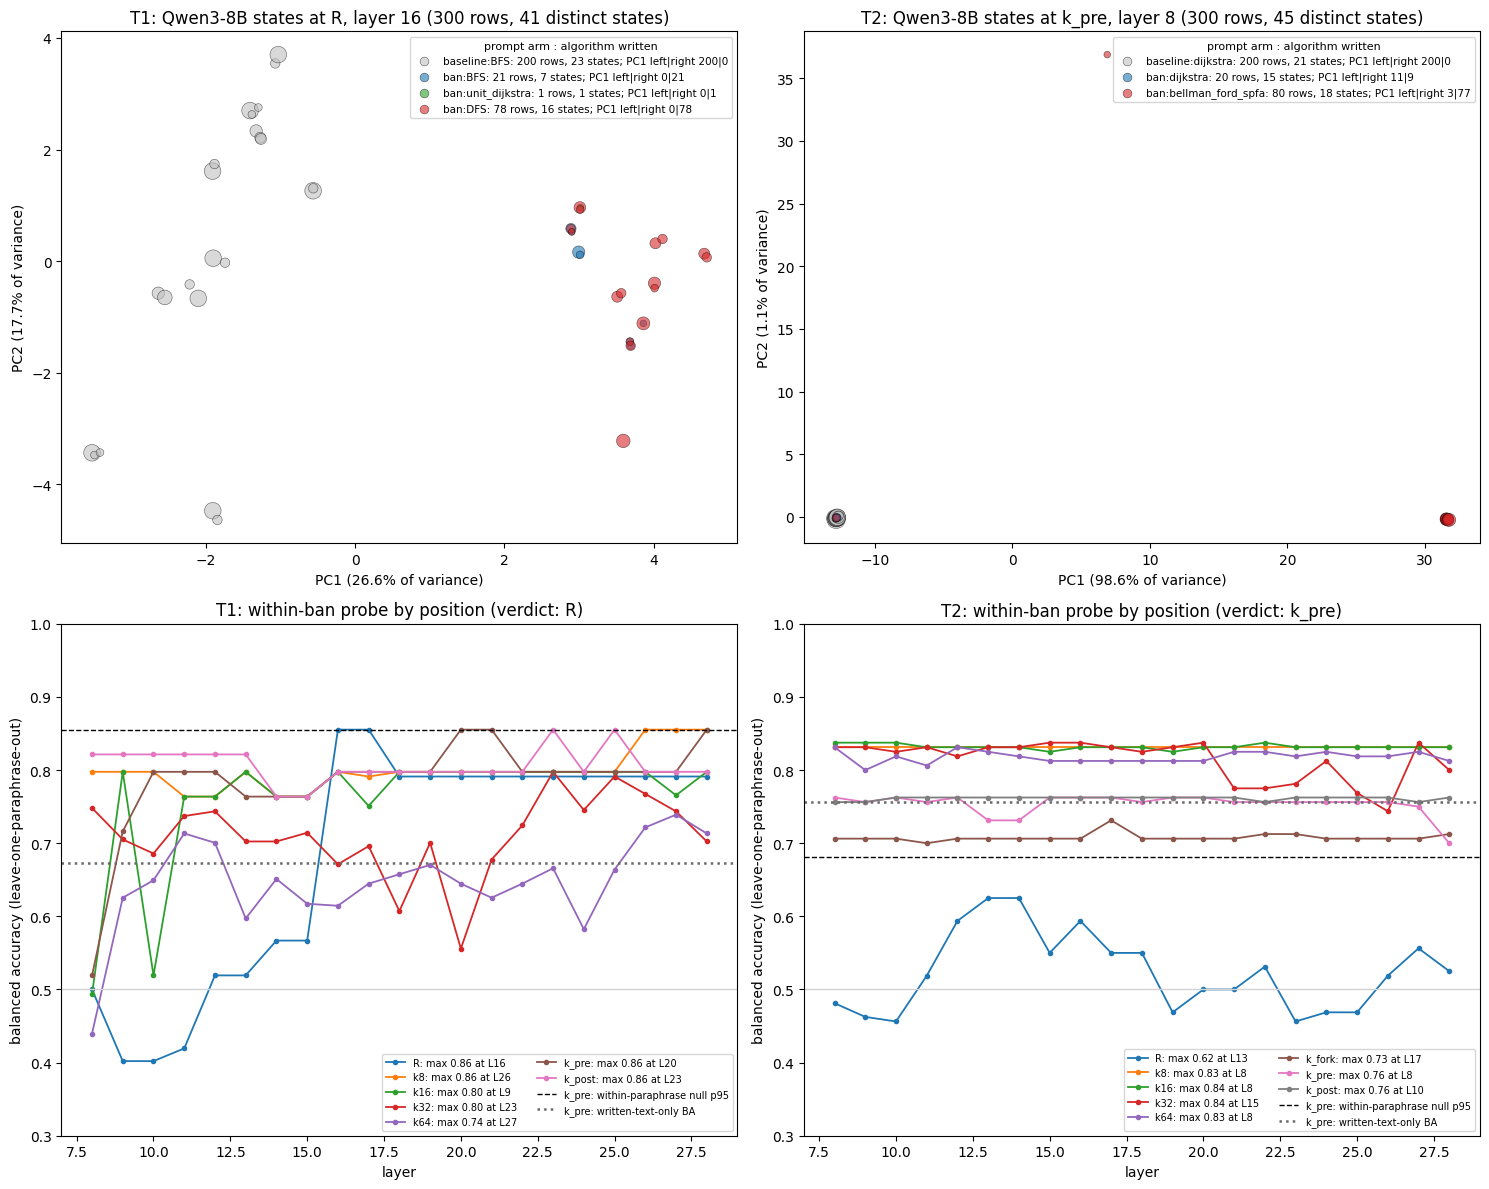

In [18]:
def tag_color(tag: str) -> str:
    """grey = baseline prompt; blue = ban prompt, default still written; red = ban prompt, substitute written; green = other."""
    arm, alg = tag.split(":", 1)
    if arm == "baseline":
        return "silver"
    return {"BFS": "tab:blue", "dijkstra": "tab:blue", "DFS": "tab:red", "bellman_ford_spfa": "tab:red"}.get(alg, "tab:green")


fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for j, t in enumerate(("T1", "T2")):
    # top: PCA of the 300 saved hidden states (the one view per task whose coordinates are in the bundle).
    # Rows sharing a paraphrase and a written prefix have identical states: one marker per distinct state, area ~ rows.
    v = next(v for v in loc["tasks"][t]["pca_views"].values() if "x" in v)
    x, y, tags = np.array(v["x"]), np.array(v["y"]), np.array(v["tag"])
    mid = (x.min() + x.max()) / 2
    ax = axes[0, j]
    for tag in sorted(set(tags), key=lambda s: (not s.startswith("baseline"), tag_color(s) == "tab:red", s)):
        m = tags == tag
        xy, cnt = np.unique(np.c_[x[m], y[m]], axis=0, return_counts=True)
        ax.scatter(xy[:, 0], xy[:, 1], s=15 + 8 * cnt, alpha=0.6, color=tag_color(tag), edgecolor="black", linewidth=0.4,
                   label=f"{tag}: {m.sum()} rows, {len(xy)} states; PC1 left|right {(x[m] < mid).sum()}|{(x[m] >= mid).sum()}")
    ax.set_xlabel(f"PC1 ({100 * v['explained'][0]:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({100 * v['explained'][1]:.1f}% of variance)")
    ax.set_title(f"{t}: Qwen3-8B states at {v['position']}, layer {v['layer']} "
                 f"({len(x)} rows, {len(np.unique(np.c_[x, y], axis=0))} distinct states)")
    leg = ax.legend(fontsize=7.5, loc="upper right", title="prompt arm : algorithm written", title_fontsize=8)
    for h in leg.legend_handles:
        h.set_sizes([40])
    # bottom: within-ban probe balanced accuracy by layer, one curve per saved position
    W = loc["tasks"][t]["contrasts"]["W"]["positions"]
    ax = axes[1, j]
    for p, pr in W.items():
        ax.plot(pr["layers"], pr["BA"], marker=".", lw=1.3, label=f"{p}: max {pr['layer_max_BA']:.2f} at L{pr['L_star']}")
    ax.axhline(W["k_pre"]["layer_max_null_within_p95"], color="black", ls="--", lw=1, label="k_pre: within-paraphrase null p95")
    ax.axhline(lsec["tasks"][t]["layer_max_table"]["k_pre"]["BA_text"], color="dimgrey", ls=":", lw=1.8, label="k_pre: written-text-only BA")
    ax.axhline(0.5, color="lightgrey", lw=1)
    ax.set_ylim(0.3, 1.0)
    ax.set_xlabel("layer")
    ax.set_ylabel("balanced accuracy (leave-one-paraphrase-out)")
    ax.set_title(f"{t}: within-ban probe by position (verdict: {lsec['tasks'][t]['mechanical_locus']})")
    ax.legend(fontsize=7, ncol=2, loc="lower right")
plt.tight_layout()
plt.show()

### Figure 2: what the knobs do to the written algorithm, and where the geometry points

**Top row.** The algorithm implemented by the correct programs under each bundled perturbation: baselines, temperature and top-k, context seeds, novelty instructions, bans, steering and generate-then-select.

**Bottom left.** Each knob's diversity (rarefied Hill-1) against its pass cost. The green box is the target region: Hill ≥ 2 at < 20 points.

**Bottom right.** How often each survivor is the geodesic-nearest neighbour of the banned default, by layer.

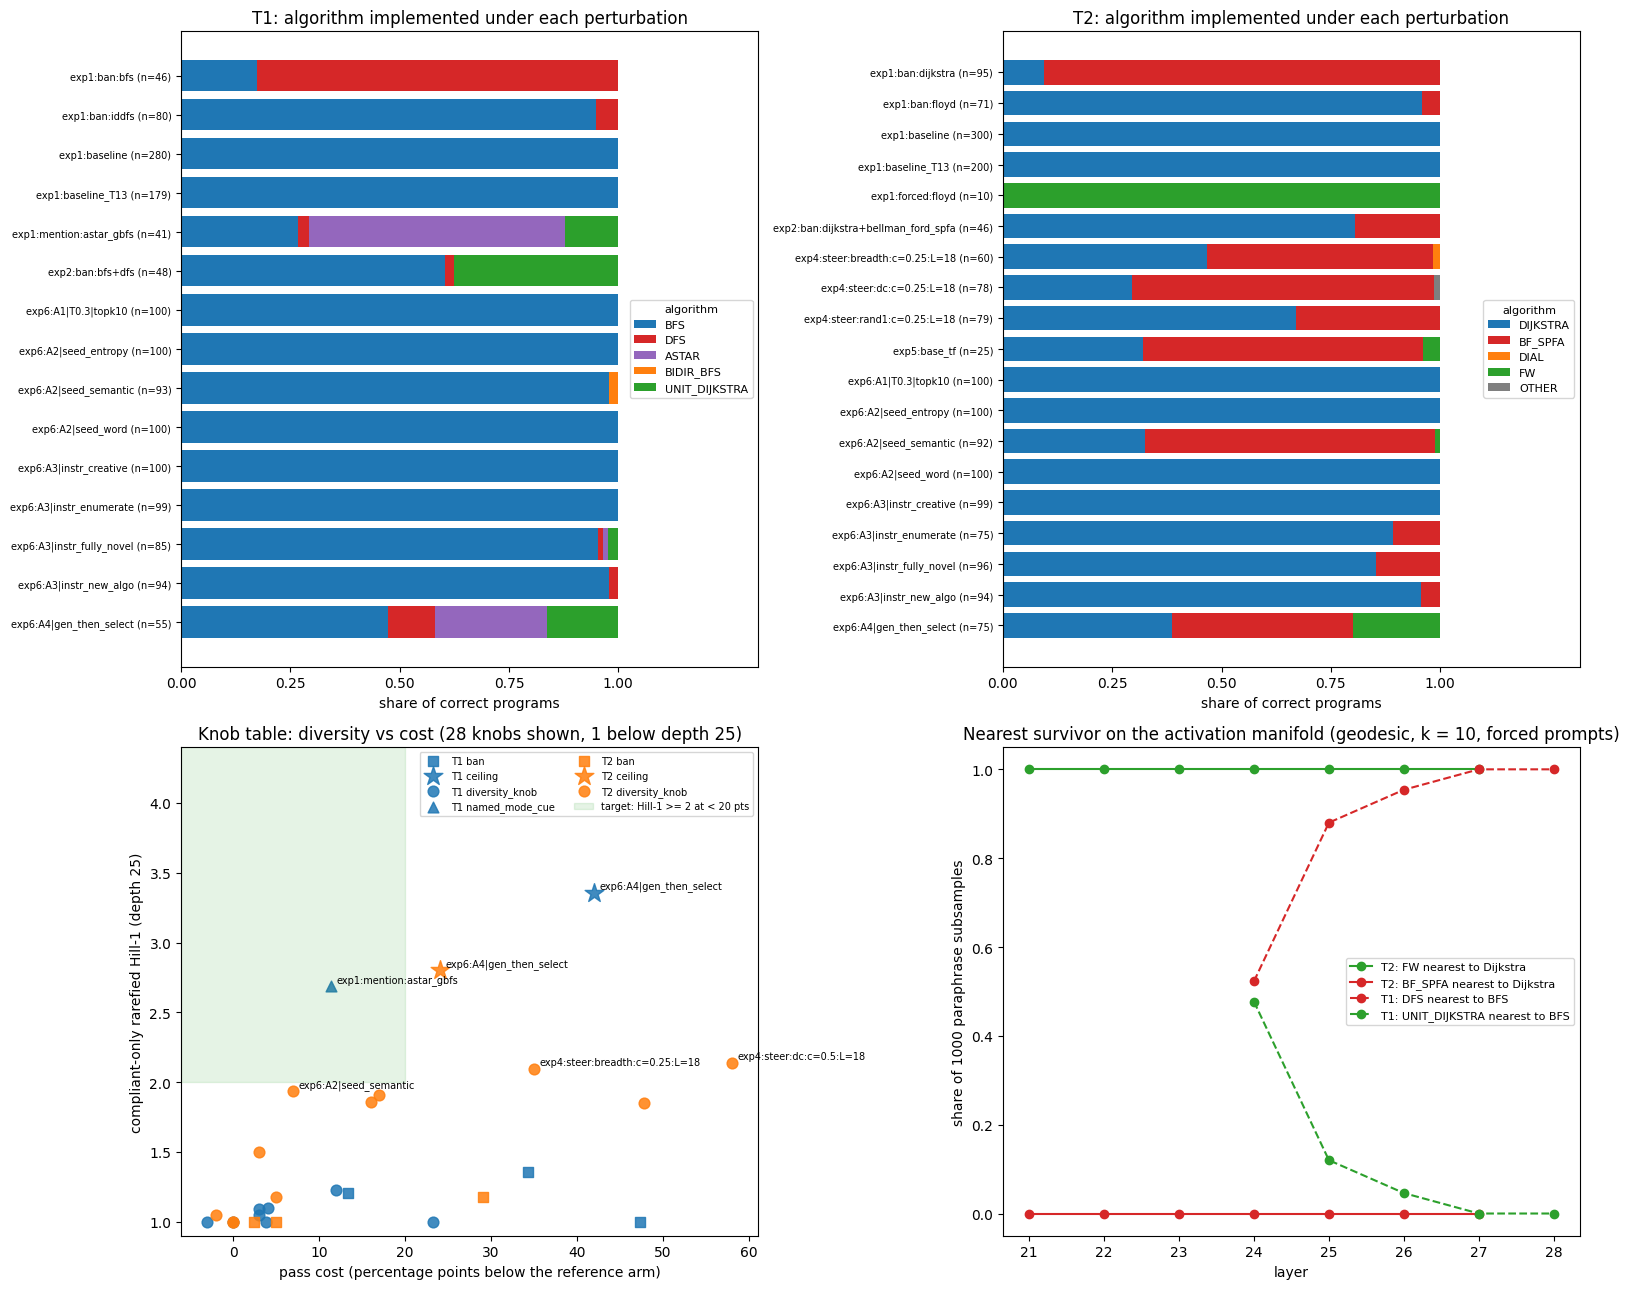

In [19]:
# one colour per algorithm, reused across tasks: blue = the task's default, red = its runner-up (the usual substitute)
ALG_COLORS = {"BFS": "tab:blue", "DIJKSTRA": "tab:blue", "DFS": "tab:red", "BF_SPFA": "tab:red",
              "UNIT_DIJKSTRA": "tab:green", "FW": "tab:green", "ASTAR": "tab:purple", "BIDIR_DIJKSTRA": "tab:purple",
              "BIDIR_BFS": "tab:orange", "DIAL": "tab:orange", "IDDFS": "tab:brown", "DAG_DP": "tab:brown"}
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])
# top: which algorithm the correct programs implement under each perturbation row in use
comps = [json.loads(s) for s in pt.composition_correct]
algs = sorted({a for c in comps for a in c}, key=lambda a: ({"BFS": 0, "DIJKSTRA": 0, "DFS": 1, "BF_SPFA": 1}.get(a, 2), a))
for j, t in enumerate(("T1", "T2")):
    ax = fig.add_subplot(gs[0, j])
    idx = [i for i in range(len(pt)) if pt.task.iloc[i] == t]
    labels = [f"{pt.experiment.iloc[i]}:{pt.condition.iloc[i]} (n={int(pt.correct.iloc[i])})" for i in idx]
    left = np.zeros(len(idx))
    for a in algs:
        share = np.array([comps[i].get(a, 0) / max(sum(comps[i].values()), 1) for i in idx])
        if share.any():
            ax.barh(labels, share, left=left, color=ALG_COLORS.get(a, "tab:gray"), label=a)
            left += share
    ax.invert_yaxis()
    ax.set_xlim(0, 1.32)  # room on the right for the legend
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xlabel("share of correct programs")
    ax.set_title(f"{t}: algorithm implemented under each perturbation")
    ax.tick_params(axis="y", labelsize=7)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=8, loc="center right", title="algorithm", title_fontsize=8)

# bottom left: knob table, diversity (rarefied Hill-1) vs pass cost
ax = fig.add_subplot(gs[1, 0])
ok = kt[np.isfinite(kt.hill1_rarefied)]
markers = {"diversity_knob": "o", "ban": "s", "named_mode_cue": "^", "ceiling": "*", "model_swap": "D"}
for (t, kc), g in ok.groupby(["task", "knob_class"]):
    ax.scatter(g.pass_points, g.hill1_rarefied, marker=markers.get(kc, "o"), s=200 if kc == "ceiling" else 60,
               color="tab:blue" if t == "T1" else "tab:orange", alpha=0.85, label=f"{t} {kc}")
for r in ok.nlargest(6, "hill1_rarefied").itertuples():
    ax.annotate(r.knob, (r.pass_points, r.hill1_rarefied), fontsize=7, xytext=(4, 3), textcoords="offset points")
x0, x1 = ax.get_xlim()
y1 = max(ax.get_ylim()[1], 4.4)
if x0 < 20:
    ax.add_patch(plt.Rectangle((x0, 2), 20 - x0, y1 - 2, color="tab:green", alpha=0.12, label="target: Hill-1 >= 2 at < 20 pts"))
ax.set_xlim(x0, x1)
ax.set_ylim(0.9, y1)
ax.set_xlabel("pass cost (percentage points below the reference arm)")
ax.set_ylabel("compliant-only rarefied Hill-1 (depth 25)")
ax.set_title(f"Knob table: diversity vs cost ({len(ok)} knobs shown, {len(kt) - len(ok)} below depth 25)")
ax.legend(fontsize=7, loc="upper right", ncol=2)

# bottom right: share of paraphrase subsamples in which each survivor is the banned default's geodesic-nearest
ax = fig.add_subplot(gs[1, 1])
for task, default, survivors, ls in (("t2", "Dijkstra", ("FW", "BF_SPFA"), "-"), ("t1", "BFS", ("DFS", "UNIT_DIJKSTRA"), "--")):
    cs = sorted((c for c in geo["grid"] if c["task"] == task and c["kind"] == "forced" and c["k"] == 10), key=lambda c: c["layer"])
    for s in survivors:
        ax.plot([c["layer"] for c in cs], [c["share_nearest"].get(s, np.nan) for c in cs], ls=ls, marker="o",
                color=ALG_COLORS.get(s, "tab:gray"), label=f"{task.upper()}: {s} nearest to {default}")
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("layer")
ax.set_ylabel("share of 1000 paraphrase subsamples")
ax.set_title("Nearest survivor on the activation manifold (geodesic, k = 10, forced prompts)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Takeaways and the full run

- **0a: when is the algorithm chosen?**
  - **T2.** Inside the ban arm, whether the model kept Dijkstra or switched to Bellman-Ford/SPFA is readable at `k_pre` (layer 8): BA 0.76, +0.28 over R, within-paraphrase p = 0.005. But the written prefix alone reaches BA 0.76: Dijkstra rows start `import heapq` and BF/SPFA rows start `from collections import deque`. In Figure 1, PC1 of those states tracks the commit index. So the verdict is **post-commit readout**: the deciding token is generated token 3, whose states (k = 1..3) were not saved. They are the next round's extraction target.
  - **T1.** R already separates DFS rows from BFS rows (BA 0.86). The within-paraphrase null absorbs it, so the signal tracks the prompt wording, not the individual sample. The mechanical verdict is **R**.
- **0b: does the manifold predict the substitute?**
  - **T2.** Floyd-Warshall, not BF/SPFA, is Dijkstra's nearest survivor in 100% of subsamples at every setting. BF/SPFA ranks 2nd or 3rd, yet it is what the model writes under a ban.
  - **T1.** DFS is nearest at layers 25-28 (88-100% of subsamples). At layer 24 the full-data order puts unit-cost Dijkstra first.
  - The audit's wording: *consistent with geodesic proximity and with typicality, not separated*. On both tasks the substitute is also the runner-up, so the geometry cannot tell the two accounts apart.
- **0d: is there a creativity knob?**
  - One statistic (rarefied Hill-1) covers temperature and top-k, context seeds, "new"/"fully novel" instructions, bans and steering. No diversity knob or ban reaches Hill ≥ 2 at under 20 pass points on either task:
    - the closest is the T2 semantic seed, 1.94 at 7 points;
    - steering on T2 passes 2 only at 35-58 points;
    - the best T1 knob is "make a fully novel algorithm", at 1.23.
  - The named-mode cue "mention A*" enters the target box (2.69 at 11 points, T1), but only by recommending one specific algorithm.
  - A ban substitutes the runner-up rather than opening the space: BF/SPFA in 272 of 272 compliant T2 programs over 5 draws.
  - Generate-then-select is the ceiling: 3.36 on T1 and 2.80 on T2, at 42 and 24 pass points.

**Scaling up.**
- **Every bundled row:** set the three `MAX_*` caps to `None` (the default here).
- **The full audit, with complete tables and the GPU locus stage:** run in the artifact's repository (`reproducibility.md` has the details):

  ```bash
  uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r requirements.txt
  export ITER1_ROOT=<folder holding gen_art_experiment_1..6>
  .venv/bin/python eval.py --rerun    # ~15 min with a GPU
  ```